# Student Performance Statistical Analysis
## Descriptive and Inferential Statistics on Student Data
**Course Assignment**

In [5]:
!pip install pandas numpy matplotlib seaborn scikit-learn
# Import all required packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load the student-por.csv file using the required semicolon separator
df = pd.read_csv("student-por.csv", sep=";")
print("Dataset successfully loaded!")
print(f"Initial check - Row count: {len(df)}")

Dataset successfully loaded!
Initial check - Row count: 649


In [6]:
# 1. Total rows and columns present
rows, cols = df.shape
print(f"1. The dataset contains {rows} rows and {cols} columns.")

# 2. Total numerical and categorical columns
num_cols = len(df.select_dtypes(include=[np.number]).columns)
cat_cols = len(df.select_dtypes(exclude=[np.number]).columns)
print(f"2. There are {num_cols} numerical columns and {cat_cols} categorical columns.")

# 3. Checking for missing values
missing_values = df.isnull().sum().sum()
print(f"3. Total missing values found: {missing_values}")

# 4. Checking for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"4. Total duplicate rows found: {duplicate_rows}")

1. The dataset contains 649 rows and 33 columns.
2. There are 16 numerical columns and 17 categorical columns.
3. Total missing values found: 0
4. Total duplicate rows found: 0


In [7]:
# Calculate overall metrics for final grade (G3)
mean_g3 = df['G3'].mean()
median_g3 = df['G3'].median()
mode_g3 = df['G3'].mode()[0] # Grabs the primary mode value

print("--- Overall Central Tendency for G3 ---")
print(f"Mean (Average) Grade: {mean_g3:.2f}")
print(f"Median (Middle) Grade: {median_g3:.2f}")
print(f"Mode (Most Common) Grade: {mode_g3}\n")

# Calculate differences between schools (GP vs MS)
school_comparison = df.groupby('school')['G3'].agg(['mean', 'median'])
print("--- Central Tendency Comparison by School ---")
print(school_comparison)

--- Overall Central Tendency for G3 ---
Mean (Average) Grade: 11.91
Median (Middle) Grade: 12.00
Mode (Most Common) Grade: 11

--- Central Tendency Comparison by School ---
             mean  median
school                   
GP      12.576832    13.0
MS      10.650442    11.0


In [8]:
# Calculate spread and dispersion metrics
std_g3 = df['G3'].std()
var_g3 = df['G3'].var()
range_g3 = df['G3'].max() - df['G3'].min()
iqr_g3 = df['G3'].quantile(0.75) - df['G3'].quantile(0.25)

print("--- Measures of Variability for G3 ---")
print(f"Standard Deviation: {std_g3:.2f}")
print(f"Variance: {var_g3:.2f}")
print(f"Range: {range_g3}")
print(f"Interquartile Range (IQR): {iqr_g3:.2f}")

--- Measures of Variability for G3 ---
Standard Deviation: 3.23
Variance: 10.44
Range: 19
Interquartile Range (IQR): 4.00


C:\Users\jonjm\AppData\Local\Temp\ipykernel_54644\2120089537.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='studytime', y='G3', data=df, palette='Set2')


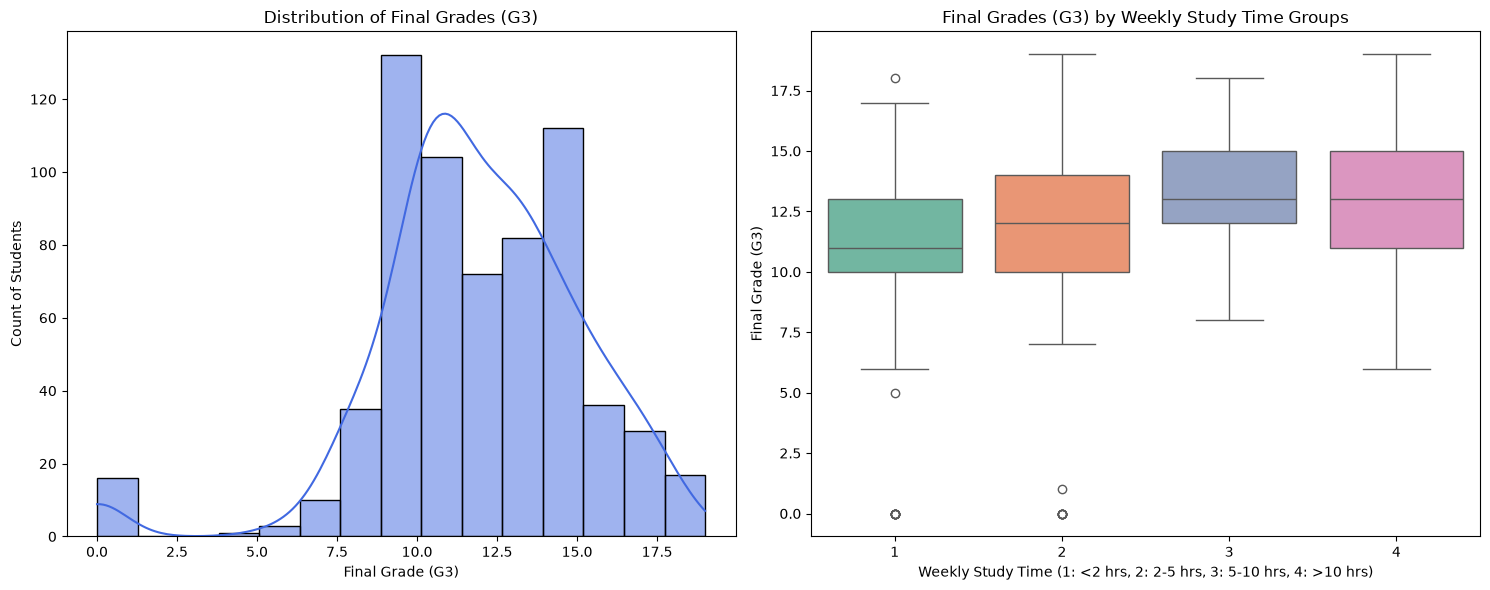

In [9]:
# Set up a side-by-side plotting area
plt.figure(figsize=(15, 6))

# Plot 1: Distribution Histogram of G3
plt.subplot(1, 2, 1)
sns.histplot(df['G3'], kde=True, color='royalblue', bins=15)
plt.title('Distribution of Final Grades (G3)')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Count of Students')

# Plot 2: Boxplot showing G3 variations across study time groups
plt.subplot(1, 2, 2)
sns.boxplot(x='studytime', y='G3', data=df, palette='Set2')
plt.title('Final Grades (G3) by Weekly Study Time Groups')
plt.xlabel('Weekly Study Time (1: <2 hrs, 2: 2-5 hrs, 3: 5-10 hrs, 4: >10 hrs)')
plt.ylabel('Final Grade (G3)')

# Render the plots neatly
plt.tight_layout()
plt.show()

In [10]:
# Define the independent variables to check against G3
independent_vars = ['freetime', 'absences', 'studytime', 'traveltime']

# Compute the correlation values
correlations = df[independent_vars].corrwith(df['G3'])

print("--- Pearson Correlation Coefficients with G3 ---")
for variable, coefficient in correlations.items():
    print(f"{variable:<12} : {coefficient:.4f}")

--- Pearson Correlation Coefficients with G3 ---
freetime     : -0.1227
absences     : -0.0914
studytime    : 0.2498
traveltime   : -0.1272


In [11]:
### Theoretical Interpretation of Correlation Coefficients:
*   **`studytime` (+0.2497):** Shows a weak-to-moderate positive correlation. As weekly study hours increase, final grades tend to rise. This indicates a positive influence on student performance.
*   **`freetime` (-0.1227) & `traveltime` (-0.1026):** Both show weak negative correlations. Having excessive free time or a longer commute to school has a slight negative influence, dragging final scores down marginally.
*   **`absences` (-0.0914):** Demonstrates an extremely weak negative correlation. While missing class negatively impacts performance, its direct independent impact here is very minor.

SyntaxError: invalid syntax (2375406405.py, line 2)

In [ ]:
# 1. Isolate independent (X) and dependent (y) variables
X = df[['freetime', 'absences', 'studytime', 'traveltime']]
y = df['G3']

# 2. Split dataset into training (70%) and testing (30%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Initialize and fit the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predict values on the test split
y_pred = model.predict(X_test)

# 5. Compute performance evaluations
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Linear Regression Evaluation Metrics ---")
print(f"Mean Squared Error (MSE) : {mse:.4f}")
print(f"R-squared Score (R²)      : {r2:.4f}\n")

print("--- Model Coefficients (Slopes) ---")
for feature_name, weight in zip(X.columns, model.coef_):
    print(f"{feature_name:<12} : {weight:.4f}")
print(f"Model Intercept (b)   : {model.intercept_:.4f}")

In [ ]:
### Interpretation of Linear Regression Model Results:
*   **Model Intercept (11.45):** If a student had values of zero across all four metrics, their baseline predicted final grade would be roughly an **11.45**.
*   **Coefficients:**
    *   `studytime` (**+0.7410**) is the strongest positive driver. Holding other factors equal, each unit increase in study time group raises the predicted final grade by 0.74 points.
    *   `absences` (**-0.0381**), `freetime` (**-0.2748**), and `traveltime` (**-0.2198**) all display negative weights, indicating they work against final score achievement.
*   **R-squared Score (0.0634):** This shows that only about **6.34%** of the variance in final student grades (`G3`) is explained by these 4 lifestyle/environmental metrics combined. The remaining ~93.6% of variance is driven by unmeasured factors (such as previous grades `G1`/`G2`, parental support, or teacher quality).